In [3]:
import xarray as xr, numpy as np, pandas as pd
import matplotlib.pyplot as plt, cartopy.crs as ccrs
import matplotlib.cm as cm, matplotlib.colors as mcolors
from matplotlib.patches import Patch
import cartopy.feature as cfeature

from functions import build_country_weights, verify_population_coverage, EU_MEMBERS,\
                        country_weights_dict, baseline_start, baseline_end, lat_to_str_dict, \
                        cider_inj_lats_popweighted, basepath, cpath, cider_combined, pop, \
                        countries_zip_path, select_eu_mode, reorient_netcdf

In [4]:
n_members = 500
newpath = basepath + f'{n_members}_members/' 

ssp_plus_invert = xr.open_dataset(newpath + 
                    f'SSP370_plus_InVERT_{n_members}member_ensemble_TREFHT_2015_to_2065.nc')

baseline = ssp_plus_invert.sel(time=slice(baseline_start, baseline_end))

In [5]:
#### Values of sensitivity-tested parameters
buffer_months = 12
tau = 12
eval_months = 36

### Where results are saved for this set of parameters
rpath = newpath + \
        f'results_buffer={buffer_months}m_tau={tau}m_eval={eval_months}m/'
print(rpath)

k_setting = 'country_k'

/home/msaenger/Perceptions_2025/cleaned_code/500_members/results_buffer=12m_tau=12m_eval=36m/


In [6]:
## Folded country polygons (labels match country_da/W_norm_eu exactly) 
countries = country_weights_dict['countries_gdf']

## Sanity check that every grid cell's population is accounted for in the country rows
verify_population_coverage(country_weights_dict)

PASSED -- Population coverage: 100.000000% (8.016736e+09 of 8.016736e+09 people-equivalent) accounted for across kept country rows.


{'population_total': 8016736089.992069,
 'population_accounted': 8016736089.992069,
 'coverage_frac': 1.0,
 'passed': True}

In [7]:
## Load min injection rate datasets computed in 05_find_min_injection_rate_..._.py

inj_rates_single_lat = xr.open_dataset(rpath + f'single_lat_min_rates_{k_setting}.nc')
inj_rates_uniform = xr.open_dataset(rpath + f'global_uniform_min_rates_{k_setting}.nc')

In [8]:
## Filter EU countries according to the chosen eu_mode

eu_mode = 'aggregated'

inj_rates_single_lat = select_eu_mode(inj_rates_single_lat, eu_mode)
inj_rates_uniform = select_eu_mode(inj_rates_uniform, eu_mode)

## Manually set all NaNs (e.g. where 250 Tg/yr was not enough to keep f below threshold) to 250 

In [9]:
def replace_nans(ds, val=250):
    
    return ds.where(~np.isnan(ds), val)

In [10]:
inj_rates_single_lat_nans_replaced = replace_nans(inj_rates_single_lat)
inj_rates_single_lat_nans_replaced.to_netcdf(rpath + \
                            f'single_lat_min_rates_{k_setting}_EU_agg_nans_replaced.nc')

In [11]:
inj_rates_uniform_nans_replaced = replace_nans(inj_rates_uniform)
inj_rates_uniform_nans_replaced.to_netcdf(rpath + \
                            f'global_uniform_min_rates_{k_setting}_EU_agg_nans_replaced.nc')

In [12]:
pctile = 0.9

nans_replaced = inj_rates_single_lat_nans_replaced.min_injection_rate.quantile(pctile, 
                                            dim='ensemble', method='higher', skipna=True) 
original = inj_rates_single_lat.min_injection_rate.quantile(pctile,
                                            dim='ensemble', method='higher', skipna=True)
test_diff = nans_replaced - original

print('Difference after replacing NaN with 250:')
for country in test_diff.country.values:
    if int(test_diff.sel(country=country).values) > 0:
        print(country, int(test_diff.sel(country=country).values))

Difference after replacing NaN with 250:
United Kingdom 3


In [13]:
nans_replaced = inj_rates_uniform_nans_replaced.min_injection_rate.quantile(pctile, 
                                            dim='ensemble', method='higher', skipna=True) 
original = inj_rates_uniform.min_injection_rate.quantile(pctile, 
                                            dim='ensemble', method='higher', skipna=True)
test_diff = nans_replaced - original

print('Difference after replacing NaN with 250:')
for country in test_diff.country.values:
    if int(test_diff.sel(country=country).values) > 0:
        print(country, int(test_diff.sel(country=country).values))

Difference after replacing NaN with 250:
United Kingdom 5


In [14]:
def plot_inj_rate_maps(inj_rate_ds, injection_type, pctile, eu_mode, vmax=None,
                       ax=None, add_colorbar=True, eu_label='European Union'):
    """
    Plot a choropleth of the Nth percentile SO2 injection rate by deploying country.
    """
    ## Compute percentile injection rate for each country across its ensemble
    pctile_injection_rate = inj_rate_ds.min_injection_rate.quantile(pctile,
                                    dim='ensemble', method='higher', skipna=True)

    ## Check how many ensemble members are 'valid' for each percentile computation
    n_valid = inj_rate_ds.min_injection_rate.notnull().sum(dim='ensemble').values
    print(n_valid)
    
    # Lookup table: country name -> selected percentile value (NaN if not in the dataset)
    pctile_lookup = dict(zip(pctile_injection_rate.country.values,
                             pctile_injection_rate.values))
    vmin = 0
    if vmax is None:
        vmax = np.nanmax(pctile_injection_rate.values)
    cmap = plt.cm.YlOrRd
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=(12, 6), subplot_kw={'projection': ccrs.Robinson()})
    ax.set_global()
    ax.set_facecolor('white')   # anything not covered by a country polygon (i.e. ocean)

    for _, row in countries.iterrows():
        name = row['ADMIN']
        if eu_mode == 'aggregated':
            eu_value = pctile_lookup.get(eu_label, np.nan) 
            value = eu_value if name in EU_MEMBERS else pctile_lookup.get(name, np.nan)
        else:
            value = pctile_lookup.get(name, np.nan)
        facecolor = 'lightgray' if np.isnan(value) else cmap(norm(value))
        ax.add_geometries([row['geometry']], crs=ccrs.PlateCarree(),
                           facecolor=facecolor, edgecolor='dimgray', linewidth=0.2)
    ax.coastlines(linewidth=0.3)
    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    if add_colorbar:
        cbar = plt.colorbar(sm, ax=ax, orientation='horizontal', pad=0.05, shrink=0.5)
        cbar.set_label('$SO_{2}$ injection rate ($Tg yr^{-1}$)')
    ax.set_title(
        f'{injection_type} injection', fontsize=20)

    return sm, pctile_injection_rate

In [25]:
def plot_inj_rate_maps_comparison(inj_rates_single_lat, inj_rates_uniform,
                                  pctile, eu_mode, vmax=None, pinatubo_rate=18.5):
    """
    Plot the single-latitude and globally-uniform injection rate maps side by side in one figure, 
    sharing one colorbar. vmax defaults to the higher of the two strategies' Nth-percentile 
    injection rates
    """
    injection_types = [('single latitude', inj_rates_single_lat),
                        ('globally uniform', inj_rates_uniform)]
    if vmax is None:
        vmax_candidates = []
        for _, ds in injection_types:
            pctile_vals = ds.min_injection_rate.quantile(pctile, 
                                        dim='ensemble', method='higher', skipna=True)
            vmax_candidates.append(np.nanmax(pctile_vals.values))
        vmax = max(vmax_candidates)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6),
                              subplot_kw={'projection': ccrs.Robinson()})
    mappable = None
    
    panel_labels = ['(a)', '(b)']
    
    inj_rates_dict = {}
    
    for ax, (injection_type, ds), panel_label in zip(axes, injection_types, panel_labels):
        mappable, inj_rates = plot_inj_rate_maps(ds, injection_type, pctile, eu_mode,
                                      vmax=vmax, ax=ax, add_colorbar=False)
        
        inj_rates_dict[injection_type] = inj_rates
        
        ax.text(0.02, 1.06, panel_label, transform=ax.transAxes,
                fontsize=18, fontweight='bold', va='top', ha='left',
                zorder=10)

    fig.subplots_adjust(bottom=0.15)
    cbar_ax = fig.add_axes([0.25, 0.06, 0.5, 0.04])  # [left, bottom, width, height]
    cbar = fig.colorbar(mappable, cax=cbar_ax, orientation='horizontal')
    cbar.set_label('$SO_{2}$ injection rate $(Tg yr^{-1})$', fontsize=16)
    cbar_ax.tick_params(labelsize=14)
    
    # ---- Mt Pinatubo reference marker ----
    if pinatubo_rate is not None and mappable.norm.vmin <= pinatubo_rate <= mappable.norm.vmax:
        # x in data units (the colorbar's value axis), y in axes fraction (1.0 = top edge of bar)
        trans = cbar_ax.get_xaxis_transform()
        cbar_ax.plot(pinatubo_rate, 0.9, marker='v', color='black', markersize=9,
                     transform=trans, clip_on=False, zorder=5)
        cbar_ax.text(pinatubo_rate, 1.5, f'Mt Pinatubo (~{pinatubo_rate} Tg)', transform=trans,
                     ha='center', va='bottom', fontsize=16)
    # --------------------------------------
    
#     plt.suptitle(f'{int(pctile*100)}th percentile injection rates',## {k_setting}', 
#                  fontsize=24, y=0.96)
    plt.tight_layout()
    
    plt.savefig(rpath + f'Plots/inj_rate_map_{int(pctile*100)}th_pctile_{k_setting}_EU_{eu_mode}.pdf',
                bbox_inches='tight')
    plt.savefig(rpath + f'Plots/inj_rate_map_{int(pctile*100)}th_pctile_{k_setting}_EU_{eu_mode}.png',
                bbox_inches='tight')
    
    return inj_rates_dict

[500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500]
[500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500]


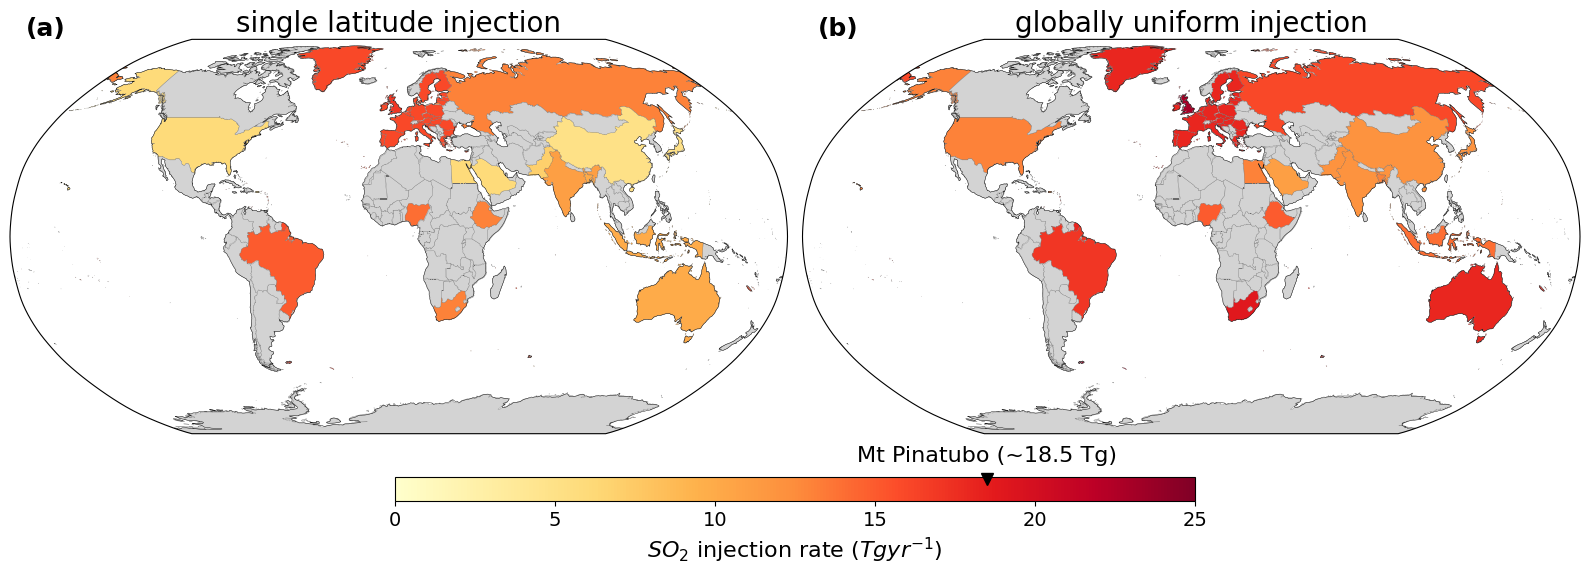

In [26]:
pctile = .9

result_dict = plot_inj_rate_maps_comparison(inj_rates_single_lat_nans_replaced, 
                              inj_rates_uniform_nans_replaced, 
                              pctile, eu_mode, vmax=25)

In [27]:
for country in result_dict['single latitude'].country.values:
    
    print(country, result_dict['single latitude'].sel(country=country).values)

Australia 10.0
Bangladesh 10.0
Brazil 15.0
China 5.0
Egypt 6.0
Ethiopia 13.0
European Union 16.0
India 11.0
Indonesia 10.0
Japan 5.0
Nigeria 14.0
Pakistan 7.0
Russia 13.0
Saudi Arabia 6.0
South Africa 13.0
United Kingdom 17.0
United States of America 6.0


In [28]:
for country in result_dict['globally uniform'].country.values:
    
    print(country, result_dict['globally uniform'].sel(country=country).values)

Australia 18.0
Bangladesh 13.0
Brazil 17.0
China 12.0
Egypt 13.0
Ethiopia 15.0
European Union 18.0
India 12.0
Indonesia 14.0
Japan 12.0
Nigeria 15.0
Pakistan 12.0
Russia 16.0
Saudi Arabia 11.0
South Africa 19.0
United Kingdom 23.0
United States of America 13.0


[500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500]
[500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500]


{'single latitude': <xarray.DataArray 'min_injection_rate' (country: 17)> Size: 136B
 array([15., 13., 24.,  7., 10., 18., 21., 14., 13.,  7., 18., 10., 18.,
         6., 20., 31., 10.])
 Coordinates:
   * country   (country) <U24 2kB 'Australia' ... 'United States of America'
     quantile  float64 8B 0.95,
 'globally uniform': <xarray.DataArray 'min_injection_rate' (country: 17)> Size: 136B
 array([28., 17., 24., 15., 21., 19., 24., 16., 17., 17., 20., 17., 24.,
        13., 26., 42., 19.])
 Coordinates:
   * country   (country) <U24 2kB 'Australia' ... 'United States of America'
     quantile  float64 8B 0.95}

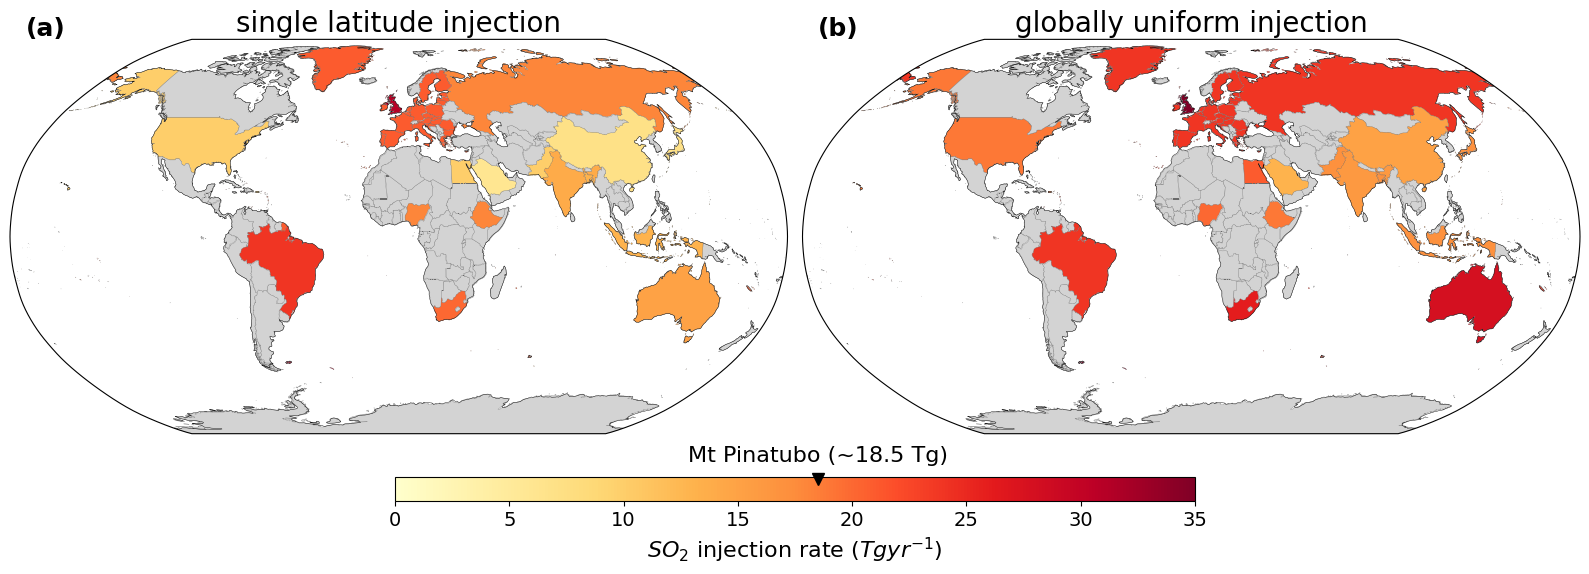

In [29]:
pctile = .95

plot_inj_rate_maps_comparison(inj_rates_single_lat_nans_replaced, 
                              inj_rates_uniform_nans_replaced, 
                              pctile, eu_mode, vmax=35)

[500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500]
[500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500 500]


{'single latitude': <xarray.DataArray 'min_injection_rate' (country: 17)> Size: 136B
 array([ 61.,  81., 250.,  65.,  25.,  41.,  71.,  37.,  30.,  25.,  94.,
         22.,  93.,  13., 250., 250.,  28.])
 Coordinates:
   * country   (country) <U24 2kB 'Australia' ... 'United States of America'
     quantile  float64 8B 1.0,
 'globally uniform': <xarray.DataArray 'min_injection_rate' (country: 17)> Size: 136B
 array([ 80.,  75., 102.,  87.,  49.,  42.,  78.,  34.,  40.,  53.,  67.,
         37., 111.,  25.,  85., 250.,  45.])
 Coordinates:
   * country   (country) <U24 2kB 'Australia' ... 'United States of America'
     quantile  float64 8B 1.0}

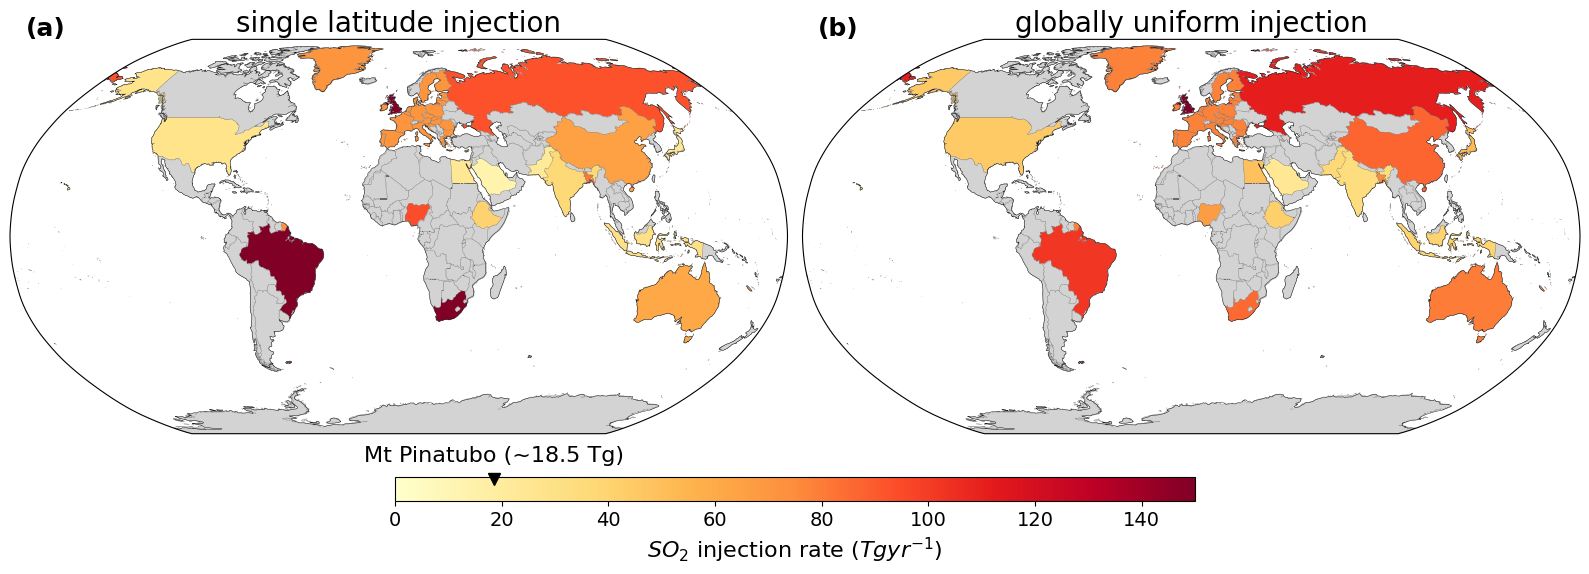

In [30]:
pctile = 1.0

plot_inj_rate_maps_comparison(inj_rates_single_lat_nans_replaced, 
                              inj_rates_uniform_nans_replaced, 
                              pctile, eu_mode, vmax=150)